In [1]:
import sys
sys.path.append('../src')

from preprocess import load_data, clean_data, encode_label, split_data

df = load_data('../data/telco_churn.csv')
df = clean_data(df)
df_encoded, encoders = encode_label(df)
X_train, X_test, y_train, y_test = split_data(df_encoded)

In [28]:
for col, le in encoders.items():
    print(f"{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

gender: {'Female': np.int64(0), 'Male': np.int64(1)}
Partner: {'No': np.int64(0), 'Yes': np.int64(1)}
Dependents: {'No': np.int64(0), 'Yes': np.int64(1)}
PhoneService: {'No': np.int64(0), 'Yes': np.int64(1)}
MultipleLines: {'No': np.int64(0), 'No phone service': np.int64(1), 'Yes': np.int64(2)}
InternetService: {'DSL': np.int64(0), 'Fiber optic': np.int64(1), 'No': np.int64(2)}
OnlineSecurity: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
OnlineBackup: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
DeviceProtection: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
TechSupport: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
StreamingTV: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
StreamingMovies: {'No': np.int64(0), 'No internet service': np.int64(1), 'Yes': np.int64(2)}
Contract: {'Month-to-month': np.int64(0), 'One year': np.int64(1), 'Two 

In [3]:
import xgboost as xgb

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 2.768561872909699


In [4]:
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42
)
xgb_model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'auc'


In [5]:
y_pred = xgb_model.predict(X_test)
y_proba = xgb_model.predict_proba(X_test)[:, 1]

In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, classification_report, confusion_matrix
)

In [7]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print("PR-AUC:", average_precision_score(y_test, y_proba))
print(classification_report(y_test, y_pred))

Accuracy: 0.7615330021291696
Precision: 0.5431818181818182
Recall: 0.6390374331550802
F1: 0.5872235872235873
ROC-AUC: 0.8164638714510837
PR-AUC: 0.6199447511627297
              precision    recall  f1-score   support

           0       0.86      0.81      0.83      1035
           1       0.54      0.64      0.59       374

    accuracy                           0.76      1409
   macro avg       0.70      0.72      0.71      1409
weighted avg       0.78      0.76      0.77      1409



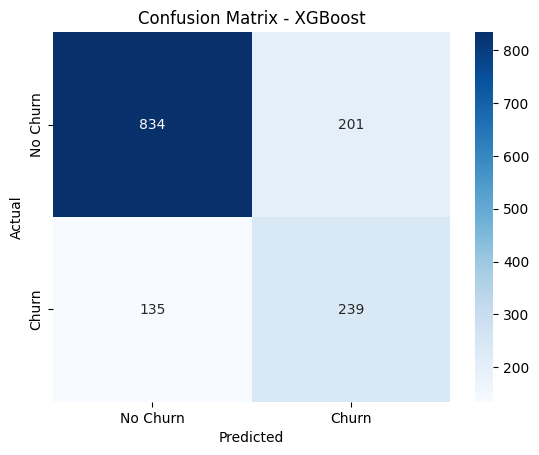

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.show()

In [15]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4],
    'learning_rate': [0.01, 0.03, 0.05],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [5, 7]
}

xgb_base = xgb.XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV ROC-AUC:", grid_search.best_score_)

xgb_tuned = grid_search.best_estimator_

Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'min_child_weight': 7, 'n_estimators': 200, 'subsample': 0.7}
Best CV ROC-AUC: 0.8488157215036889


In [16]:
y_pred_tuned = xgb_tuned.predict(X_test)
y_proba_tuned = xgb_tuned.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_tuned))
print("Precision:", precision_score(y_test, y_pred_tuned))
print("Recall:", recall_score(y_test, y_pred_tuned))
print("F1:", f1_score(y_test, y_pred_tuned))
print("ROC-AUC:", roc_auc_score(y_test, y_proba_tuned))
print("PR-AUC:", average_precision_score(y_test, y_proba_tuned))

Accuracy: 0.7444996451383961
Precision: 0.5119047619047619
Recall: 0.8048128342245989
F1: 0.6257796257796258
ROC-AUC: 0.8484228473998295
PR-AUC: 0.6645813888110328


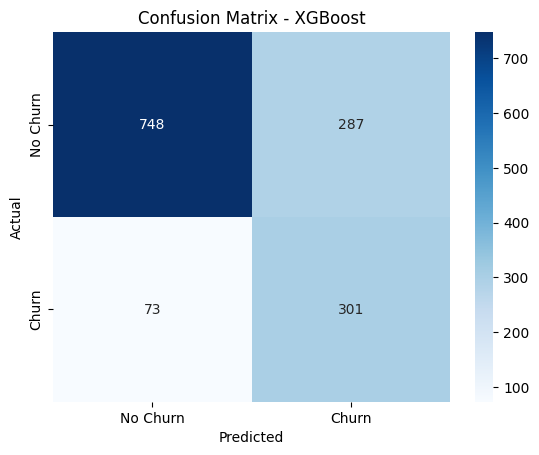

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - XGBoost')
plt.show()

In [20]:
import shap

explainer = shap.TreeExplainer(xgb_tuned)
shap_values = explainer(X_test)

c:\Users\prasa\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


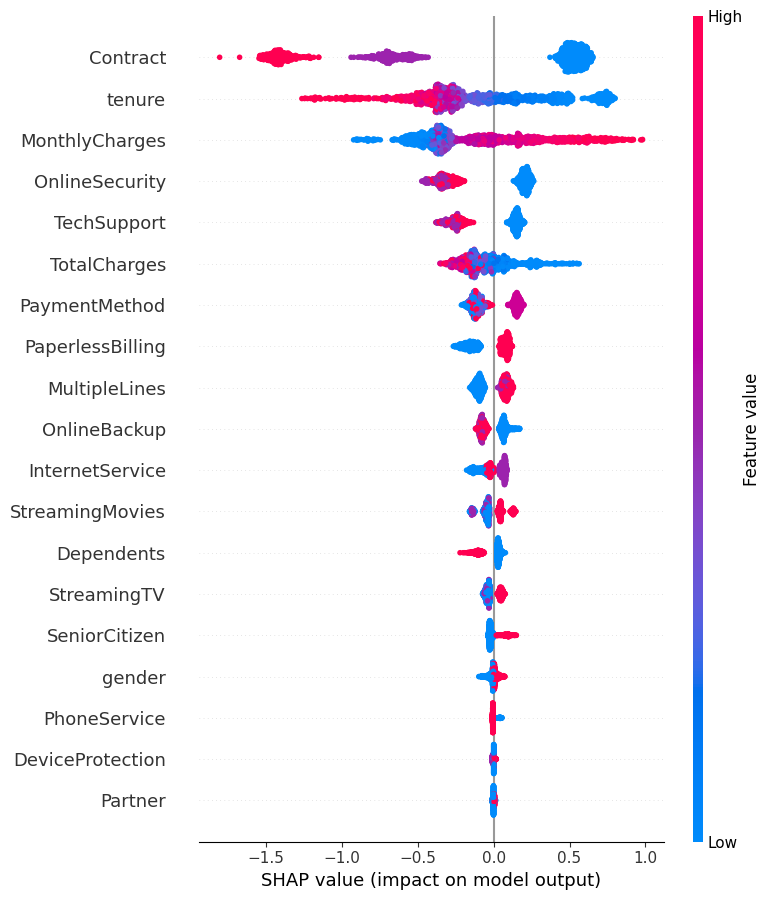

In [21]:
shap.summary_plot(shap_values, X_test)

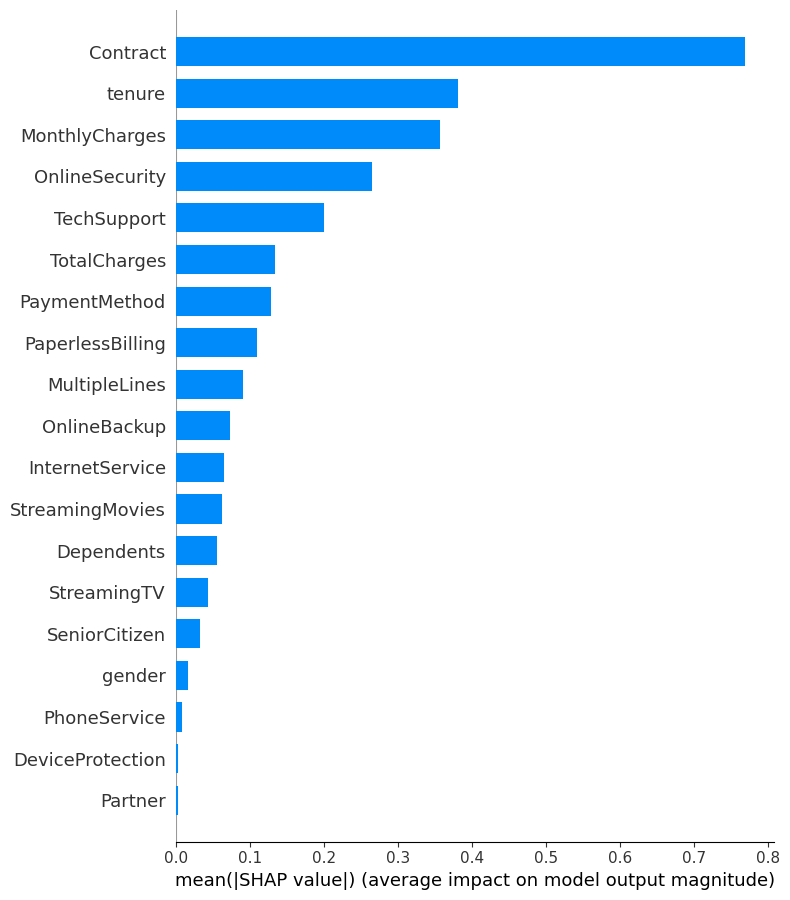

In [22]:
shap.summary_plot(shap_values, X_test, plot_type='bar')

Top feature: Contract


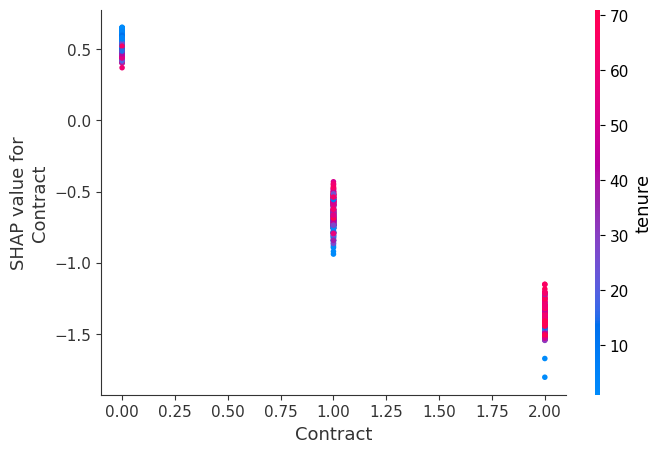

In [24]:
import numpy as np

mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
top_feature_idx = mean_abs_shap.argmax()
top_feature = X_test.columns[top_feature_idx]
print("Top feature:", top_feature)

shap.dependence_plot(top_feature, shap_values.values, X_test)

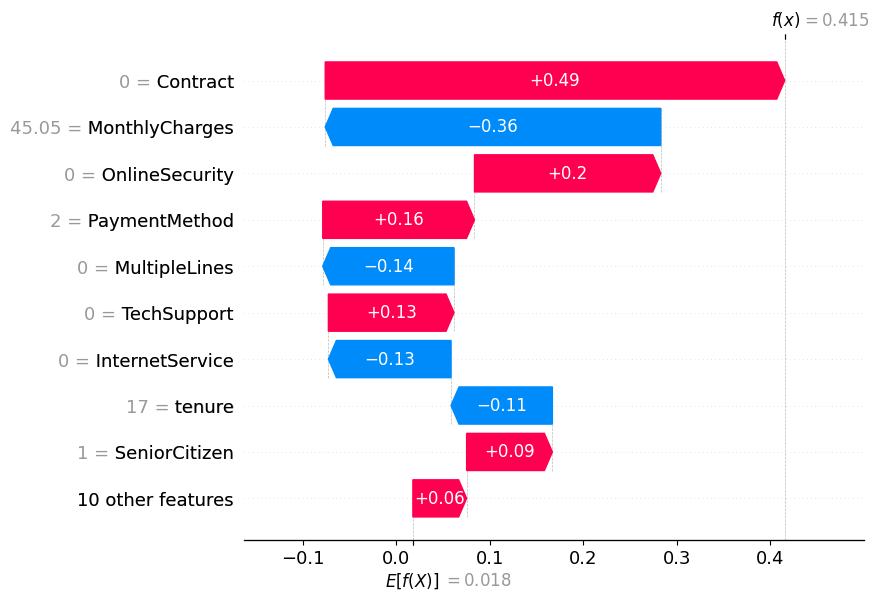

In [27]:
churned_customers = np.where(y_test.values == 1)[0]
sample_idx = churned_customers[0]

shap.plots.waterfall(shap_values[sample_idx])

In [29]:
import joblib
import os

os.makedirs('../outputs', exist_ok=True)

xgb_tuned.save_model('../outputs/xgb_model.json')
joblib.dump(encoders, '../outputs/encoders.pkl')

['../outputs/encoders.pkl']